In [1]:
import pandas as pd
import seaborn as sns
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
ion = pd.read_csv('ion.csv', index_col=0)
ion.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V26,V27,V28,V29,V30,V31,V32,V33,V34,Class
1,1,0,0.99539,-0.05889,0.85243,0.02306,0.83398,-0.37708,1.00000,0.03760,...,-0.51171,0.41078,-0.46168,0.21266,-0.34090,0.42267,-0.54487,0.18641,-0.45300,good
2,1,0,1.00000,-0.18829,0.93035,-0.36156,-0.10868,-0.93597,1.00000,-0.04549,...,-0.26569,-0.20468,-0.18401,-0.19040,-0.11593,-0.16626,-0.06288,-0.13738,-0.02447,bad
3,1,0,1.00000,-0.03365,1.00000,0.00485,1.00000,-0.12062,0.88965,0.01198,...,-0.40220,0.58984,-0.22145,0.43100,-0.17365,0.60436,-0.24180,0.56045,-0.38238,good
4,1,0,1.00000,-0.45161,1.00000,1.00000,0.71216,-1.00000,0.00000,0.00000,...,0.90695,0.51613,1.00000,1.00000,-0.20099,0.25682,1.00000,-0.32382,1.00000,bad
5,1,0,1.00000,-0.02401,0.94140,0.06531,0.92106,-0.23255,0.77152,-0.16399,...,-0.65158,0.13290,-0.53206,0.02431,-0.62197,-0.05707,-0.59573,-0.04608,-0.65697,good


In [3]:
ion.shape # (rows, columns)

(351, 35)

In [4]:
ion = ion.drop_duplicates()
ion = ion.dropna()
ion.shape

(350, 35)

In [5]:
ion.describe().T

,count,mean,std,min,25%,50%,75%,max
V1,350.0,0.894286,0.307912,0.0,1.000000,1.000000,1.000000,1.0
V2,350.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0
V3,350.0,0.643174,0.497234,-1.0,0.473448,0.873445,1.000000,1.0
V4,350.0,0.044499,0.442060,-1.0,-0.065388,0.016700,0.194727,1.0
V5,350.0,0.602785,0.519608,-1.0,0.415473,0.811145,1.000000,1.0
V6,350.0,0.116220,0.461428,-1.0,-0.024868,0.022930,0.335317,1.0
V7,350.0,0.551667,0.492477,-1.0,0.219745,0.729315,0.970445,1.0
V8,350.0,0.119701,0.521456,-1.0,-0.055235,0.015085,0.451572,1.0
V9,350.0,0.513311,0.507050,-1.0,0.093298,0.686450,0.954185,1.0
V10,350.0,0.181864,0.484446,-1.0,-0.049003,0.020665,0.536192,1.0


In [6]:
ion['Class'].value_counts().sort_index()

Class
bad     125
good    225
Name: count, dtype: int64

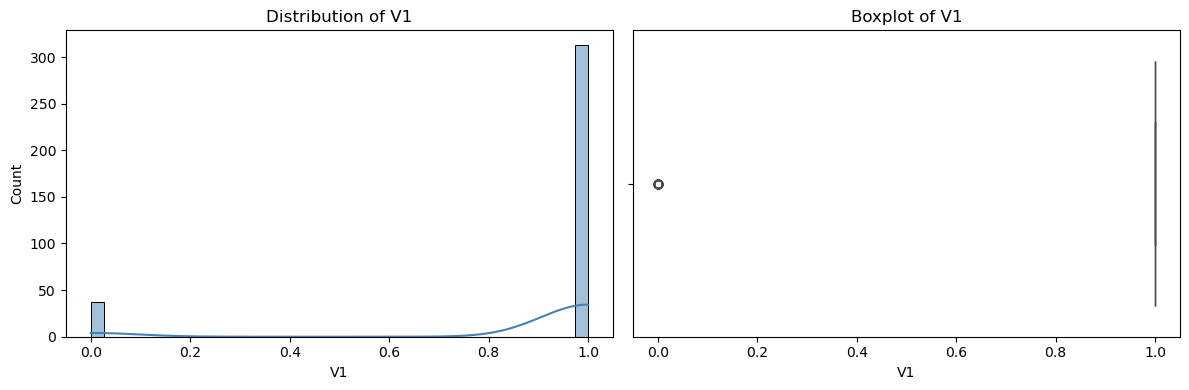

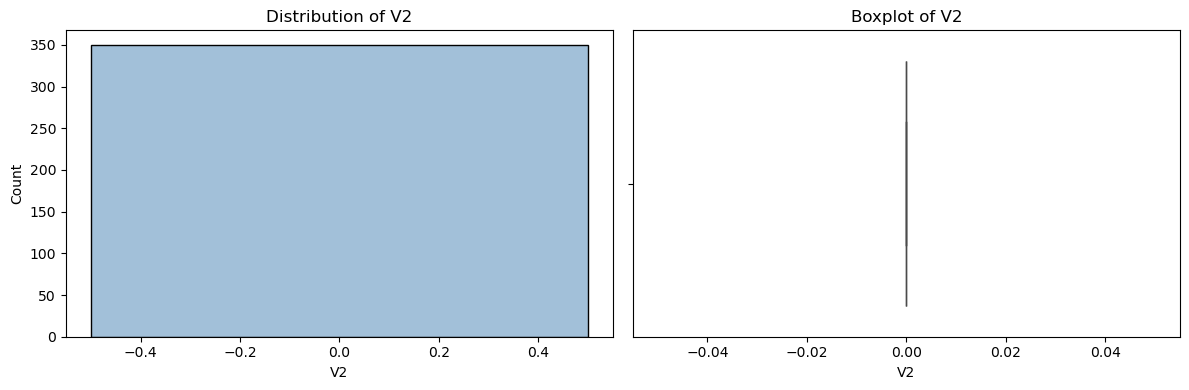

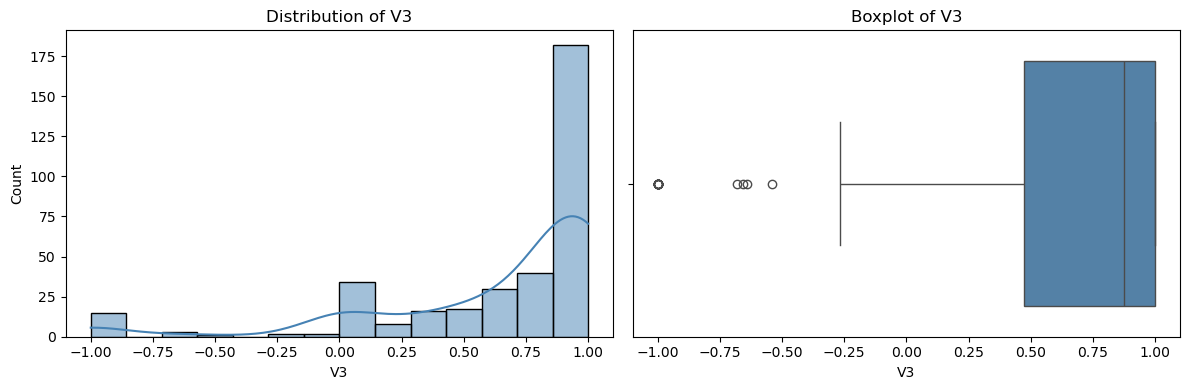

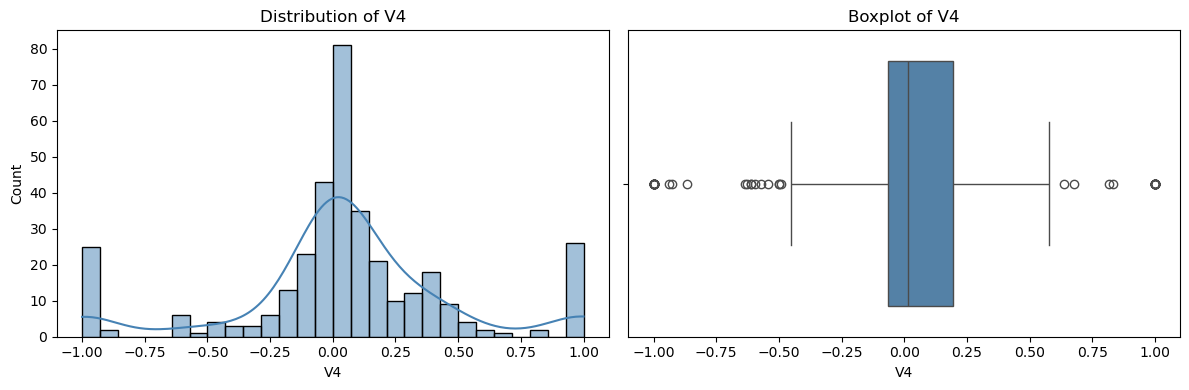

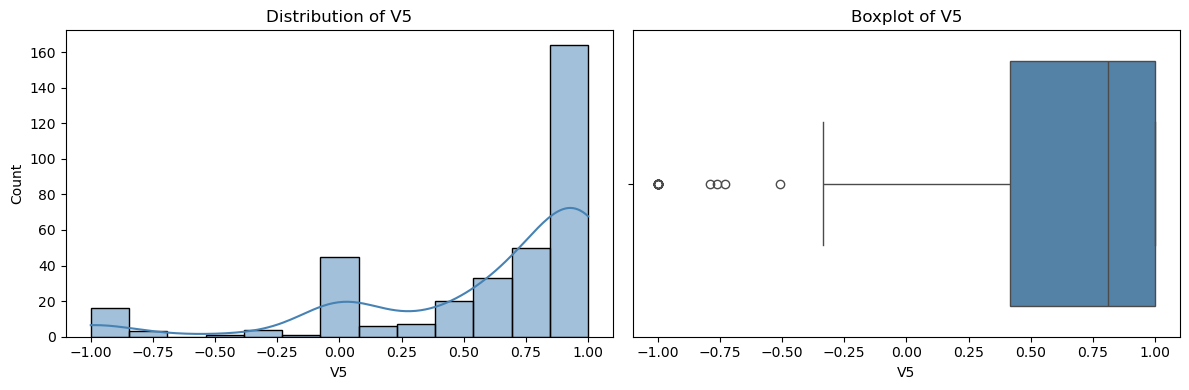

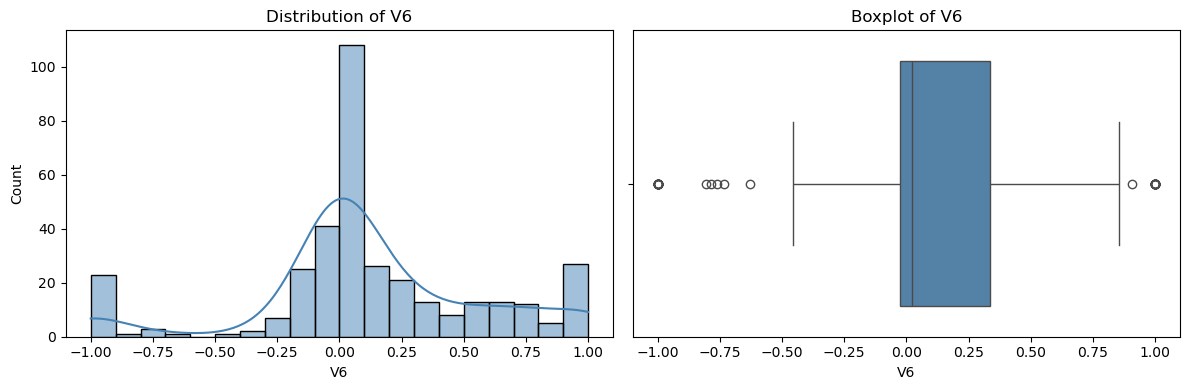

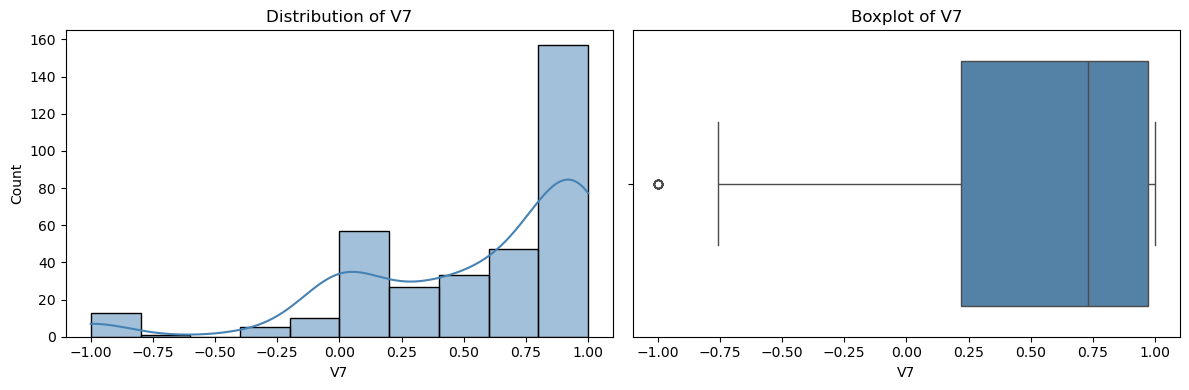

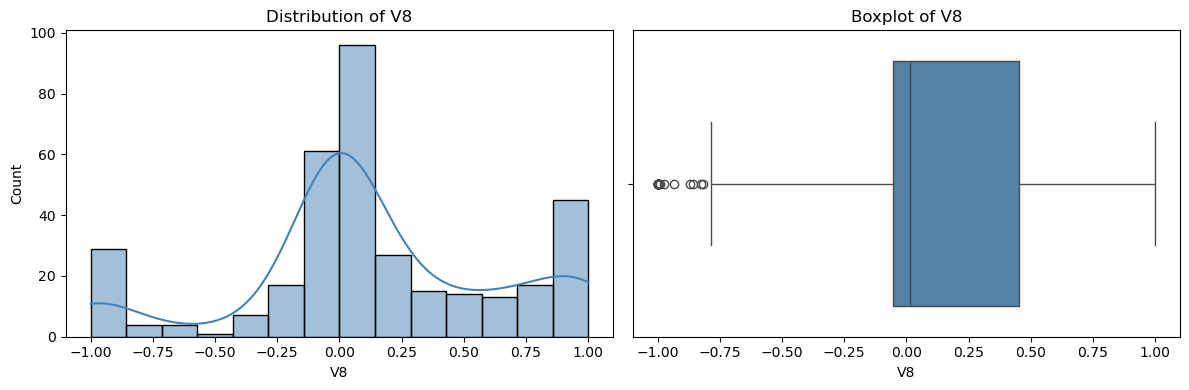

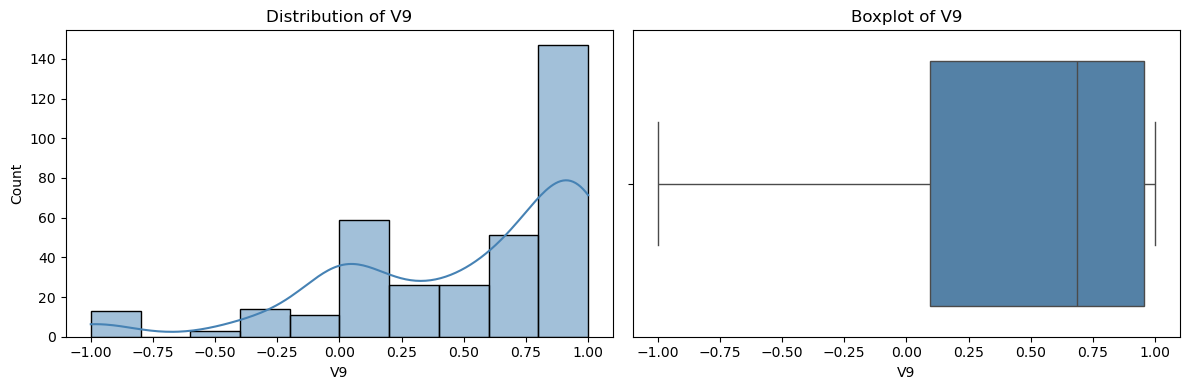

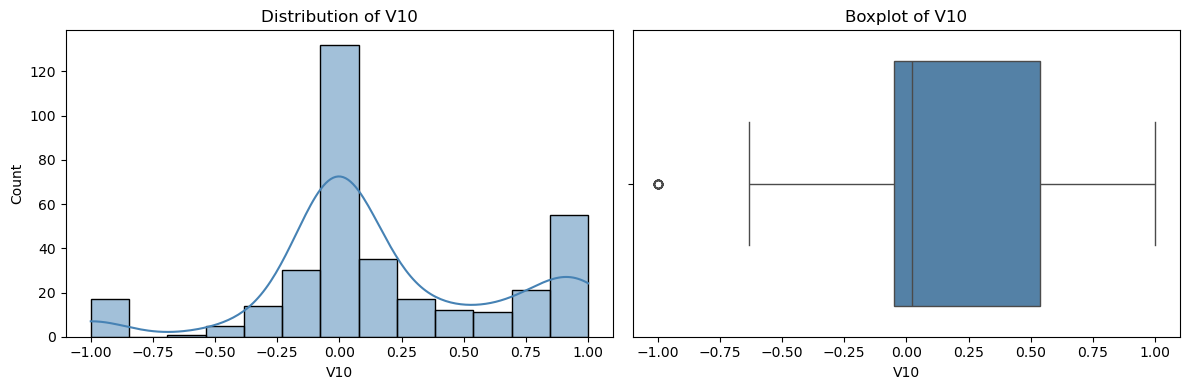

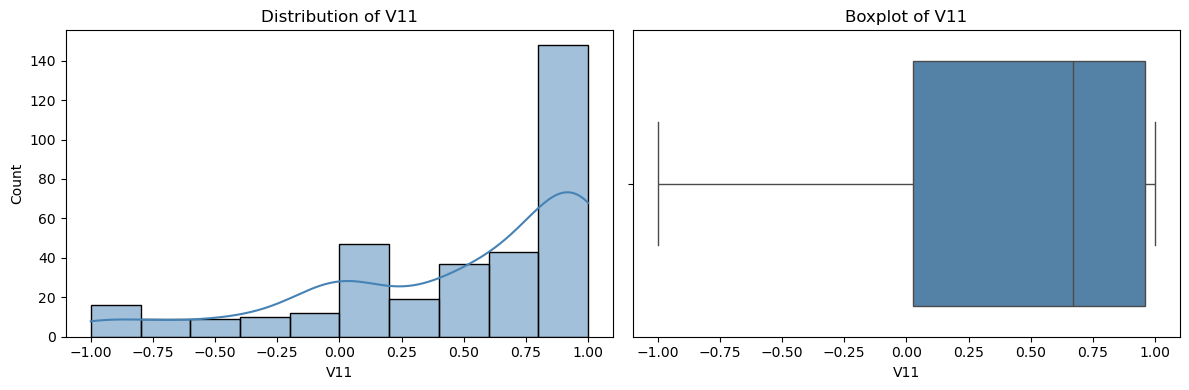

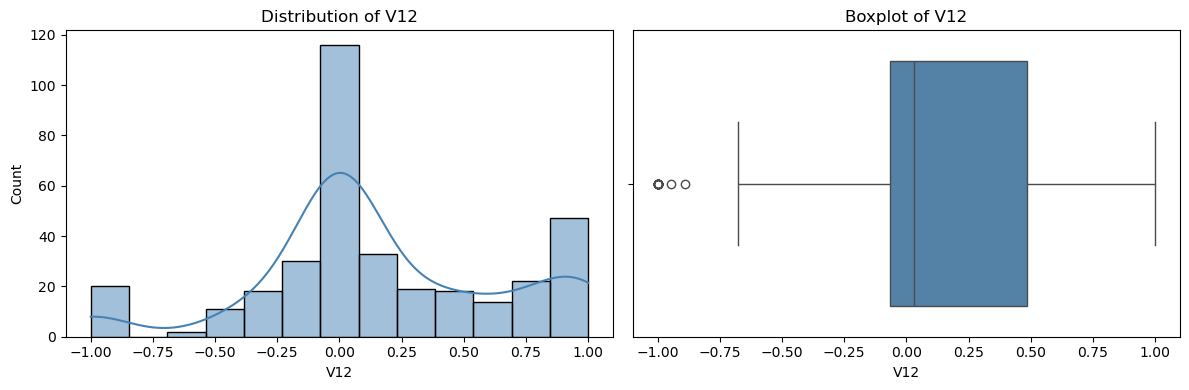

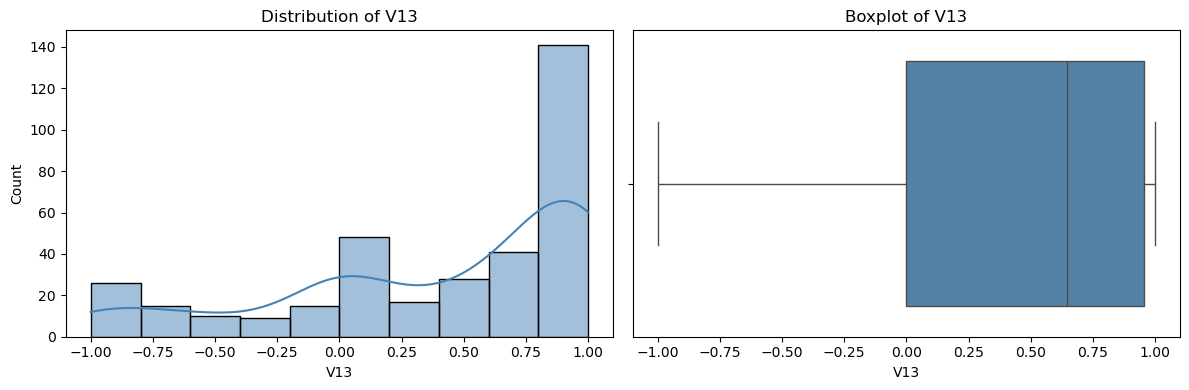

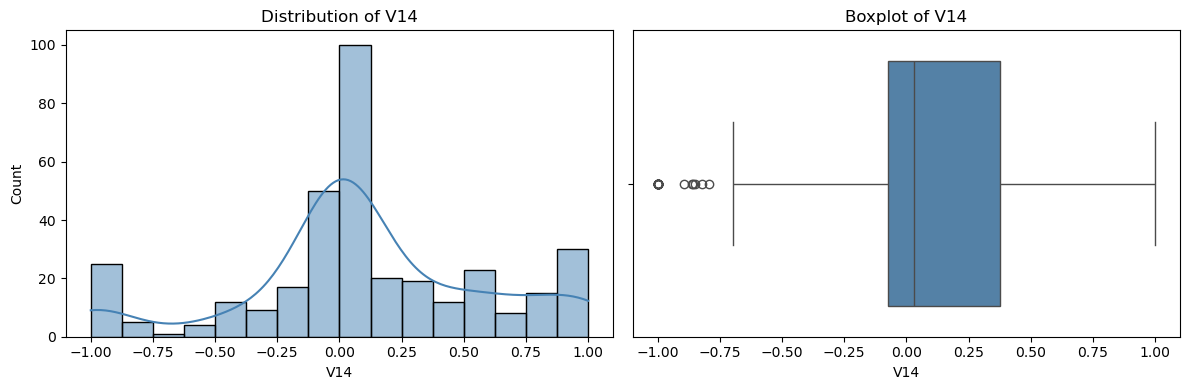

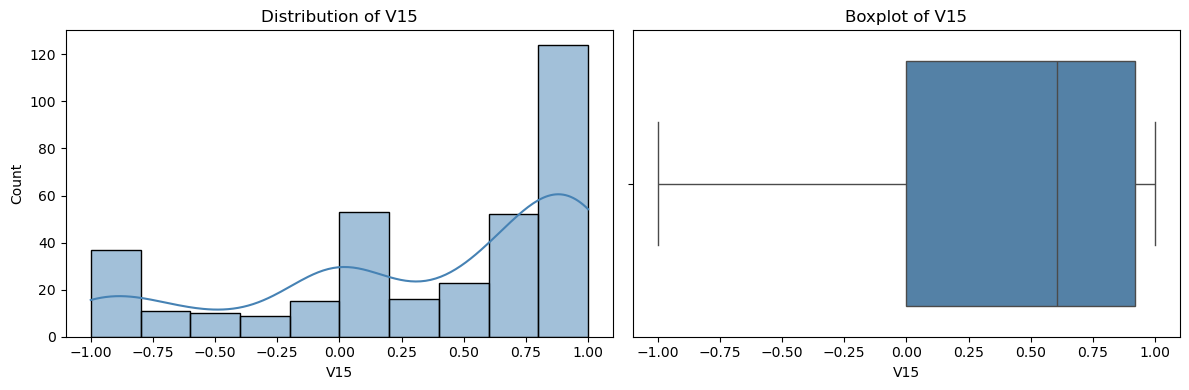

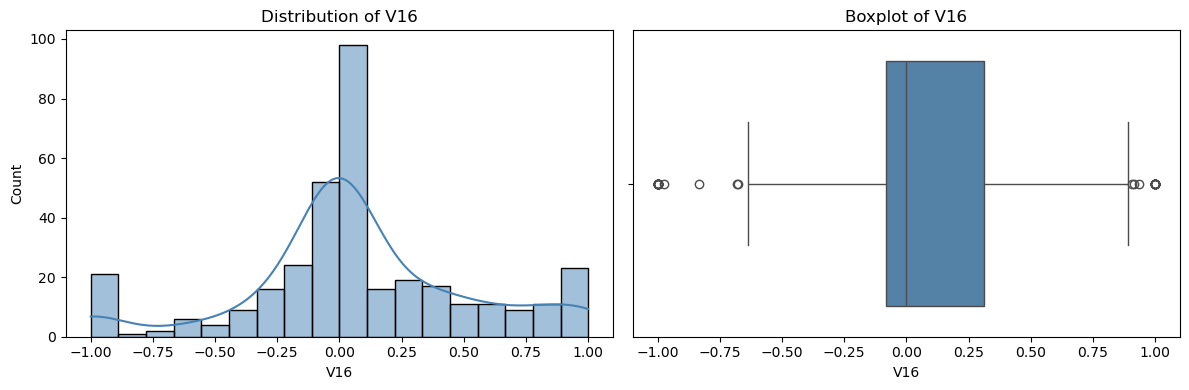

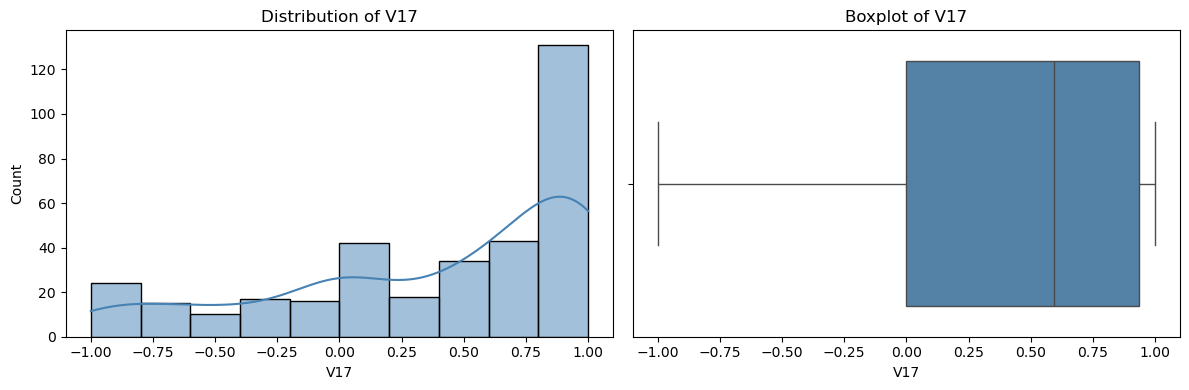

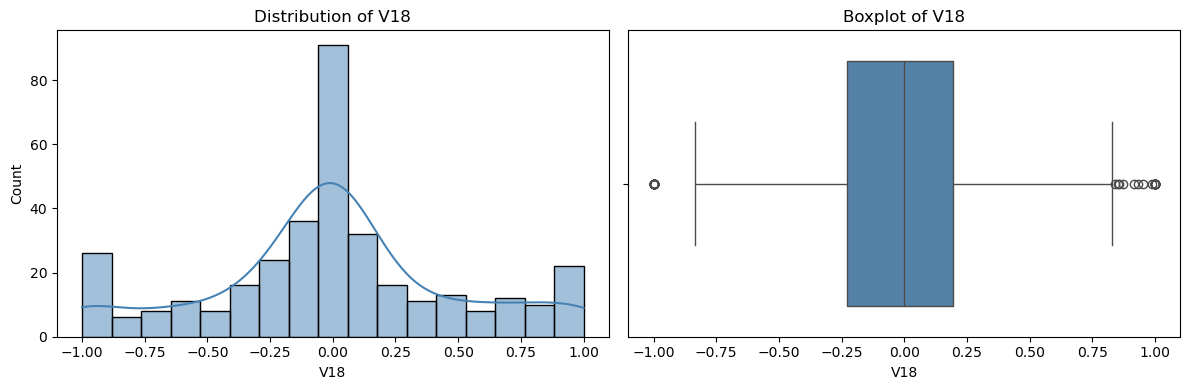

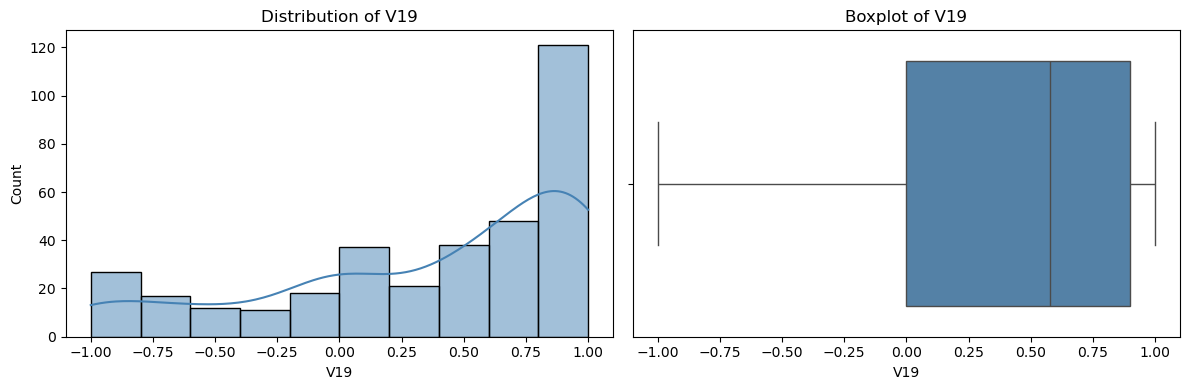

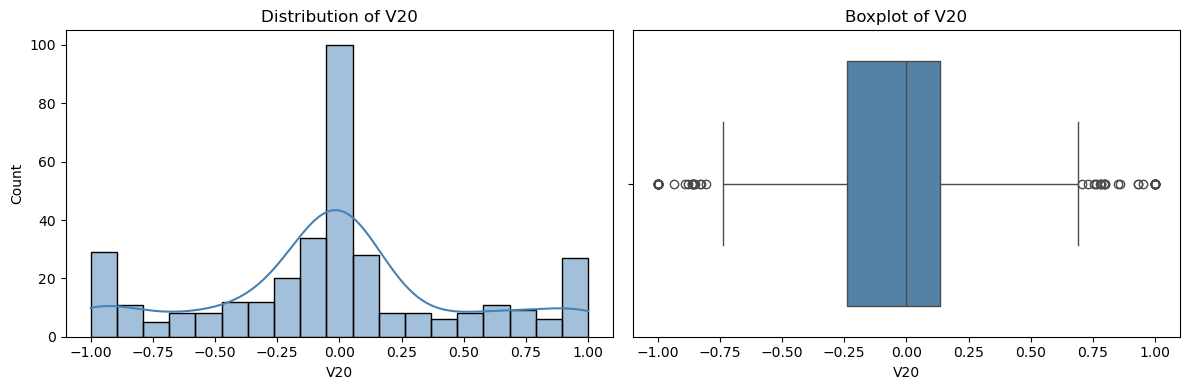

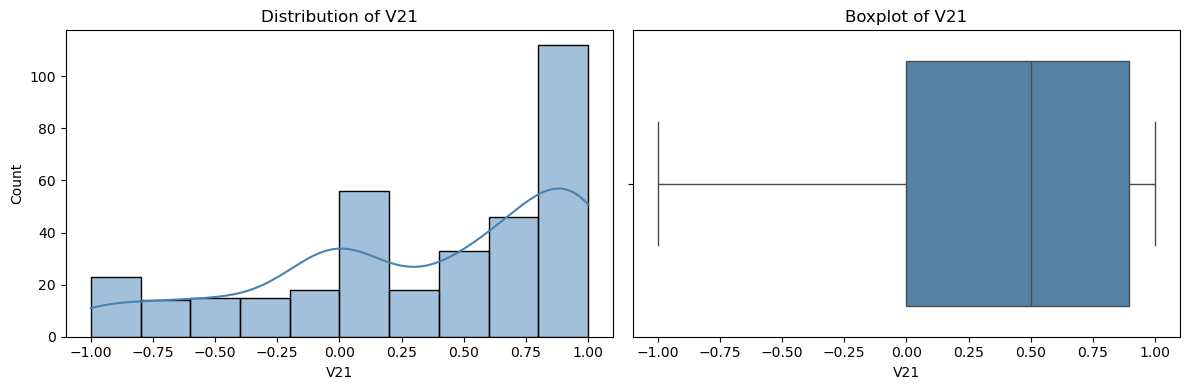

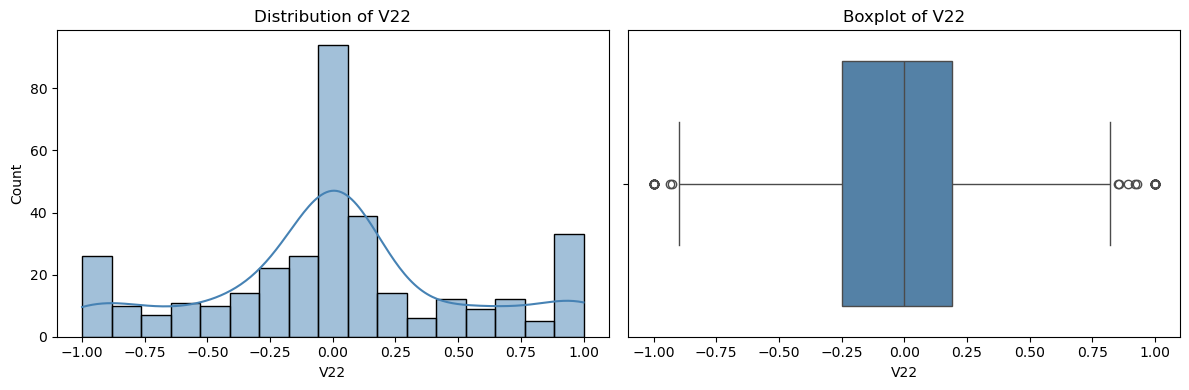

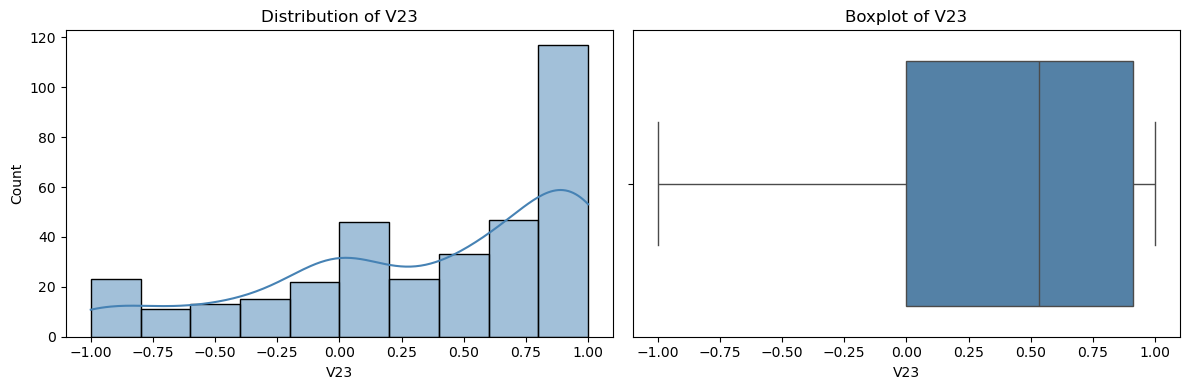

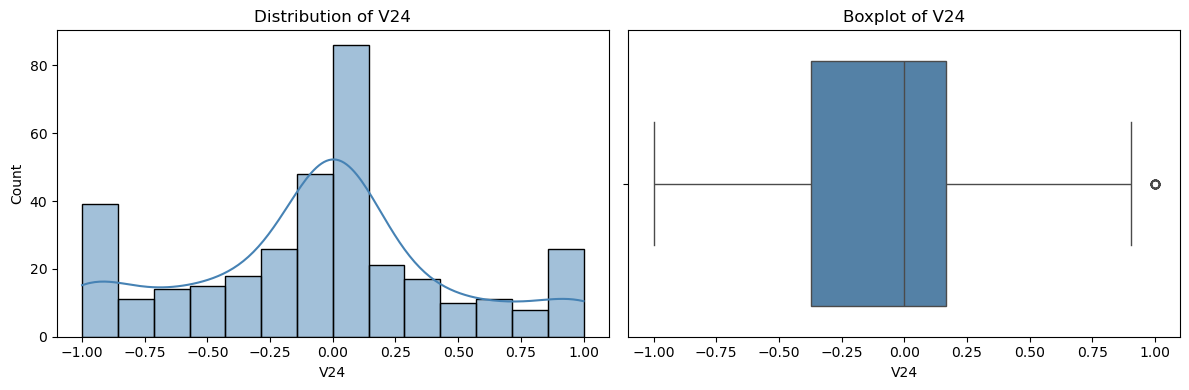

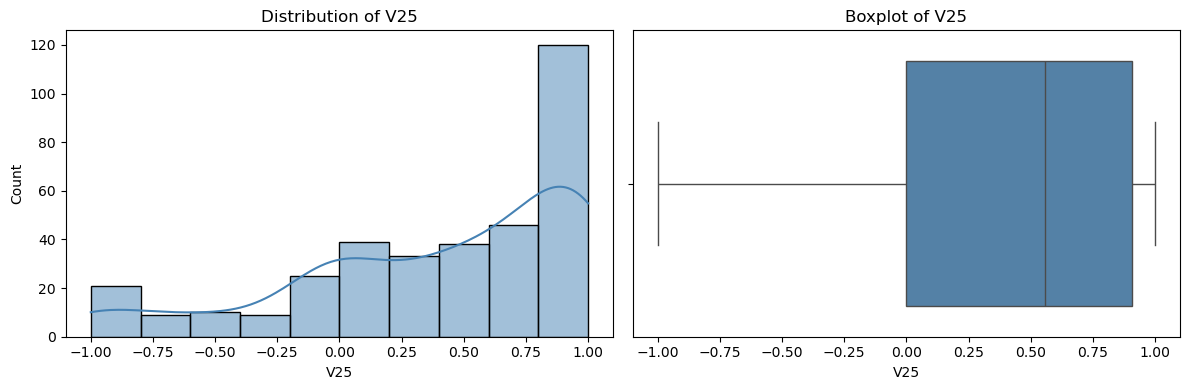

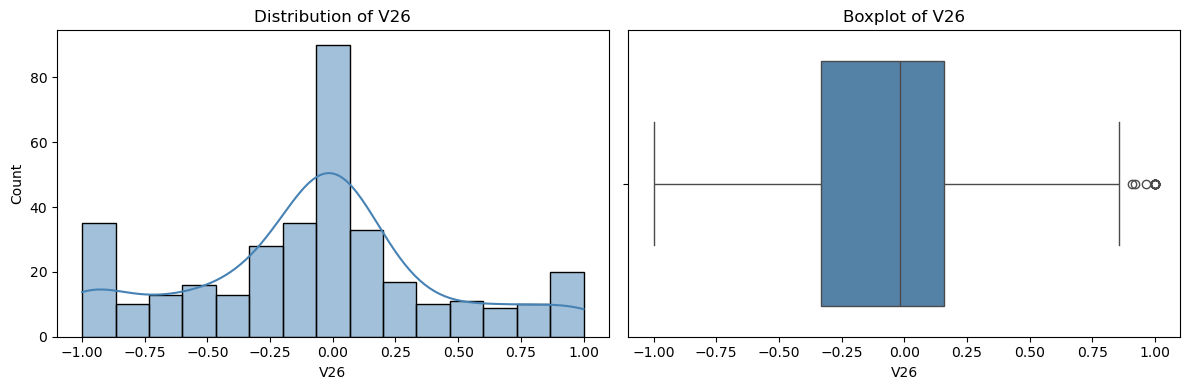

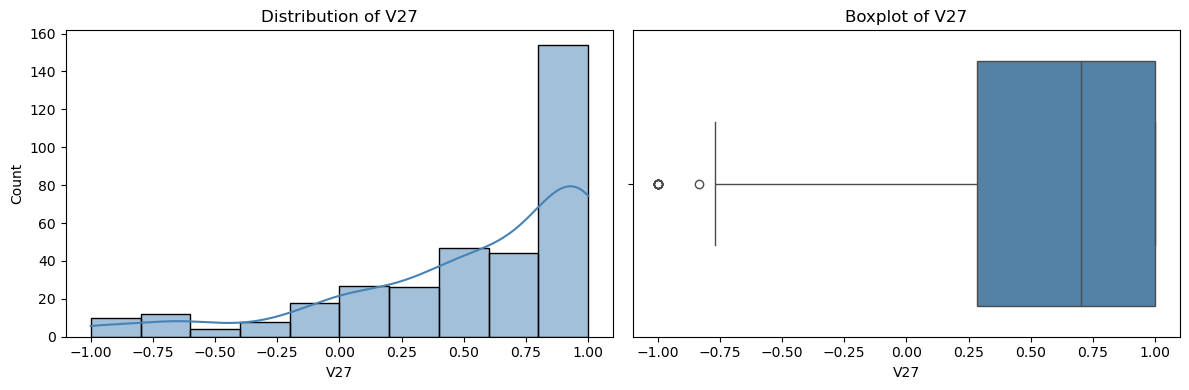

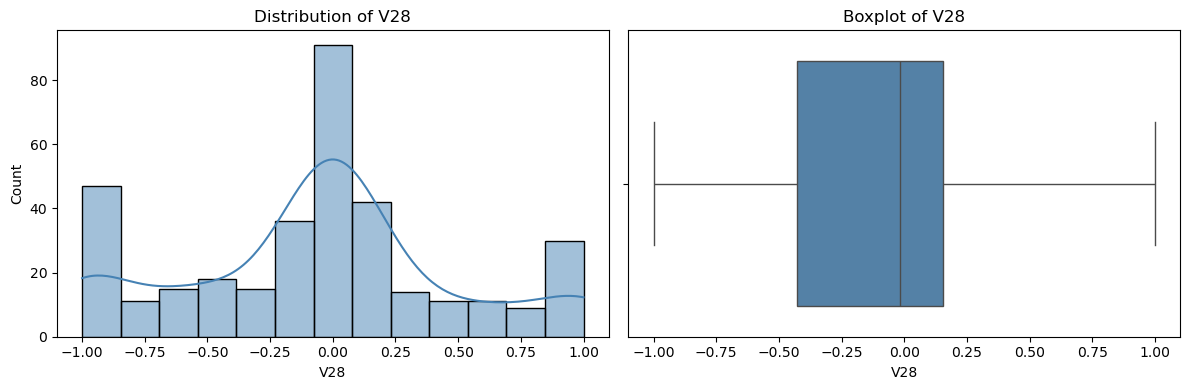

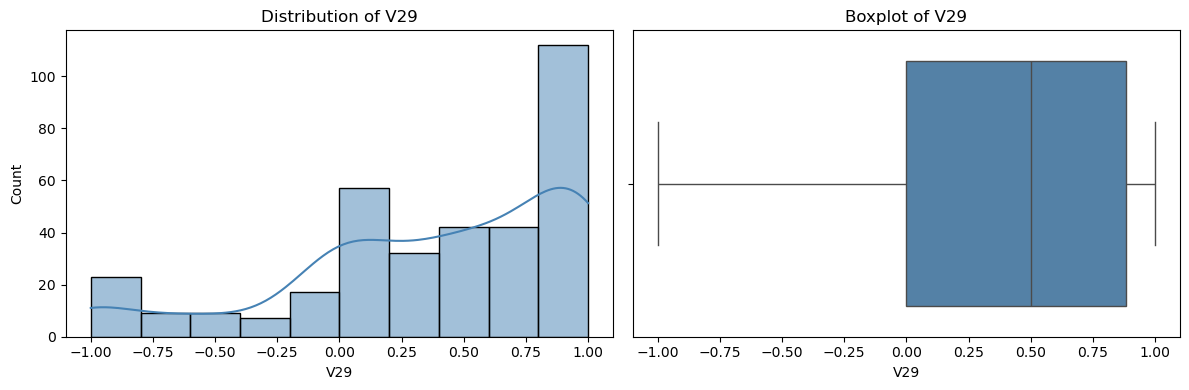

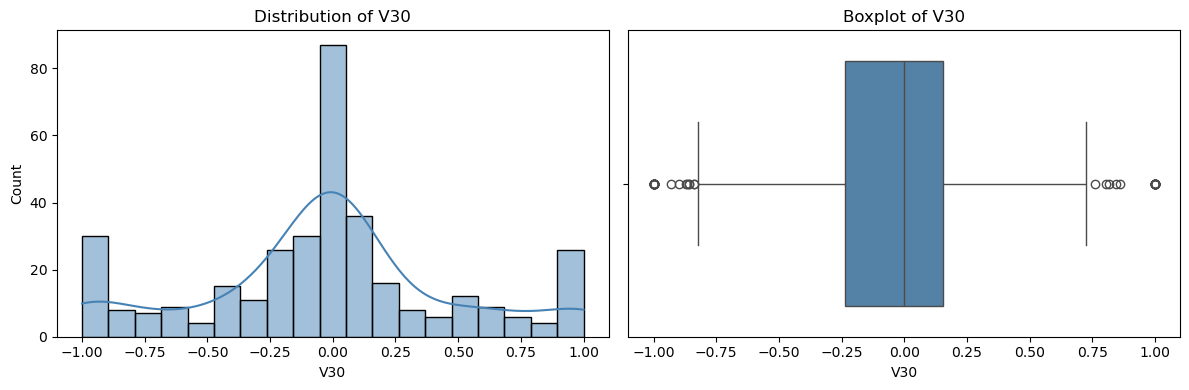

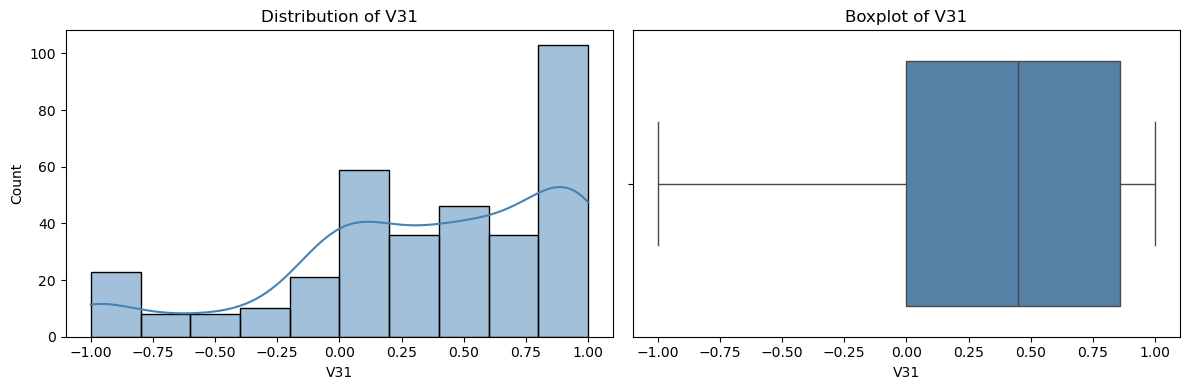

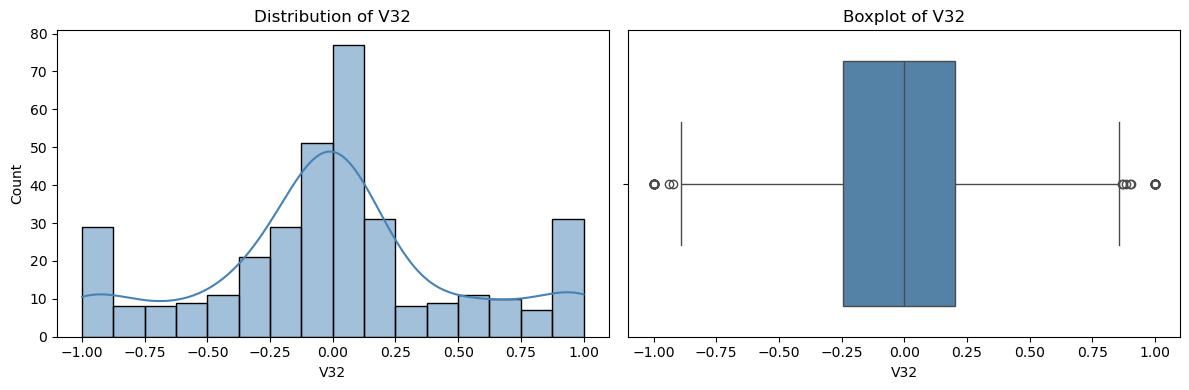

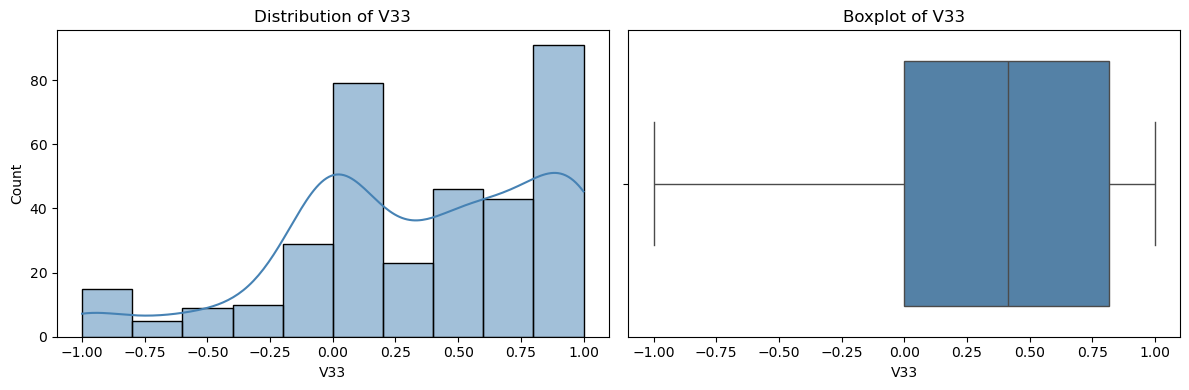

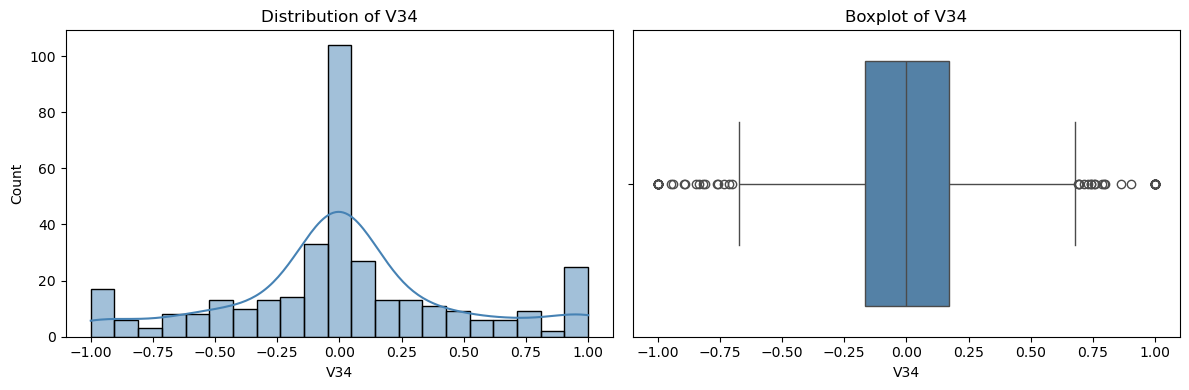

In [7]:
numerical_cols = ion.columns.drop('Class')

for col in numerical_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(ion[col], kde=True, ax=axes[0], color="steelblue")
    sns.boxplot(x=ion[col], ax=axes[1], color="steelblue")
    axes[0].set_title(f"Distribution of {col}")
    axes[1].set_title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

In [8]:

df = ion.copy()
df['Class'] = df['Class'].map({'good': 0, 'bad': 1})

df_train = df.sample(frac=0.7, random_state=0)
df_valid = df.drop(df_train.index)

max_ = df_train.max(axis=0)
min_ = df_train.min(axis=0)

df_train = (df_train - min_) / (max_ - min_)
df_valid = (df_valid - min_) / (max_ - min_)
df_train.dropna(axis=1, inplace=True) # drop the empty feature in column 2
df_valid.dropna(axis=1, inplace=True)

X_train = df_train.drop('Class', axis=1)
X_valid = df_valid.drop('Class', axis=1)
y_train = df_train['Class']
y_valid = df_valid['Class']



In [9]:
from tensorflow import keras
from tensorflow.keras import layers

input_shape = (X_train.shape[1],) 
model = keras.Sequential([
    layers.Dense(4, activation='relu', input_shape=input_shape),
    layers.Dense(4, activation='relu'),    
    layers.Dense(1, activation='sigmoid'),
])

C:\Users\CS-DEXTER.VOON\AppData\Local\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 161 (644.00 B)

 Trainable params: 161 (644.00 B)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['binary_accuracy'],
)

In [12]:
early_stopping = keras.callbacks.EarlyStopping(
    patience=10,
    min_delta=0.001,
    restore_best_weights=True,
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=512,
    epochs=1000,
    callbacks=[early_stopping],
    verbose=0, # hide the output because we have so many epochs
)

Best Validation Loss: 0.4867
Best Validation Accuracy: 0.8095


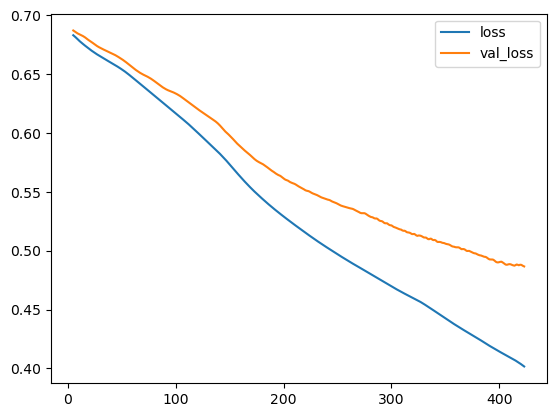

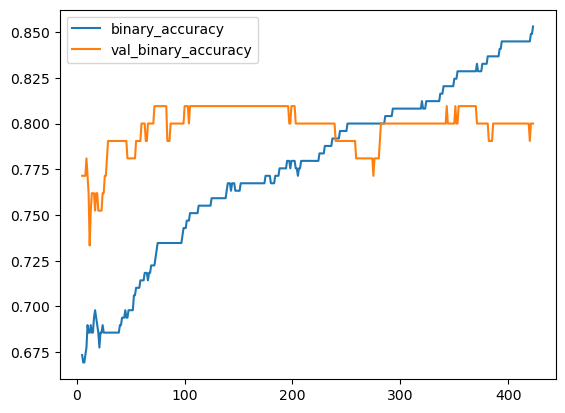

In [13]:
history_df = pd.DataFrame(history.history)
# Start the plot at epoch 5
history_df.loc[5:, ['loss', 'val_loss']].plot()
history_df.loc[5:, ['binary_accuracy', 'val_binary_accuracy']].plot()

print(("Best Validation Loss: {:0.4f}" +\
      "\nBest Validation Accuracy: {:0.4f}")\
      .format(history_df['val_loss'].min(), 
              history_df['val_binary_accuracy'].max()))

In [15]:

test_loss, test_accuracy = model.evaluate(X_valid, y_valid, verbose=0)
print(f"\nTest validation loss: {test_loss:.3f}")
print(f"\nTest validation accuracy: {test_accuracy:.3f}")
# Make predictions on first 5 test samples
predictions = model.predict(X_valid[:5])
for actual, pred in zip(y_valid[:5], predictions.flatten()):
    print(f"Actual Quality: {actual} | Predicted: {pred:.2f}")


Test validation loss: 0.488

Test validation accuracy: 0.800
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
Actual Quality: 0.0 | Predicted: 0.41
Actual Quality: 1.0 | Predicted: 0.41
Actual Quality: 1.0 | Predicted: 1.00
Actual Quality: 1.0 | Predicted: 0.41
Actual Quality: 0.0 | Predicted: 0.55
